# Student Performance Analysis

## Project Overview

This project explores student performance in mathematics using the UCI Student Performance dataset.

The goal is to analyze students' final grades, weekly study time, and absences using Python, Pandas, and Matplotlib.

## Dataset

- **Source:** UCI Machine Learning Repository
- **File:** `student-mat.csv`
- **Number of students:** 395
- **Final grade:** `G3`, on a scale from 0 to 20

## Questions

1. What is the distribution of students' final math grades?
2. How does average final grade vary across weekly study-time groups?
3. How do average final grades compare between students with more than five absences and those with five or fewer absences?

## Loading and Exploring the Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("student-mat.csv", sep=";")

In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
df.shape

(395, 33)

In [5]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [7]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

## Selecting and Filtering Data

In [8]:
df["G3"]

0       6
1       6
2      10
3      15
4      10
       ..
390     9
391    16
392     7
393    10
394     9
Name: G3, Length: 395, dtype: int64

In [9]:
df[["G1", "G2", "G3"]]

,G1,G2,G3
0,5,6,6
1,5,5,6
2,7,8,10
3,15,14,15
4,6,10,10
...,...,...,...
390,9,9,9
391,14,16,16
392,10,8,7
393,11,12,10


In [10]:
df[["studytime", "absences"]]

,studytime,absences
0,2,6
1,2,4
2,2,10
3,3,2
4,2,4
...,...,...
390,2,11
391,1,3
392,1,3
393,1,0


In [11]:
df[df["G3"] > 15]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,16,18,19
14,GP,M,15,U,GT3,A,2,2,other,other,...,4,5,2,1,1,3,0,14,16,16
22,GP,M,16,U,LE3,T,4,2,teacher,other,...,4,5,1,1,3,5,2,15,15,16
31,GP,M,15,U,GT3,T,4,4,services,services,...,4,3,1,1,1,5,0,17,16,17
32,GP,M,15,R,GT3,T,4,3,teacher,at_home,...,4,5,2,1,1,5,0,17,16,16
36,GP,M,15,U,LE3,T,4,3,teacher,services,...,5,4,3,1,1,4,2,15,16,18
42,GP,M,15,U,GT3,T,4,4,services,teacher,...,4,3,3,1,1,5,2,19,18,18
47,GP,M,16,U,GT3,T,4,3,health,services,...,4,2,2,1,1,2,4,19,19,20
59,GP,F,16,U,GT3,T,4,2,services,other,...,4,2,3,1,1,5,2,15,16,16
69,GP,F,15,R,LE3,T,3,1,other,other,...,4,4,2,2,3,3,12,16,16,16


In [12]:
df[df["absences"] > 10]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
18,GP,M,17,U,GT3,T,3,2,services,services,...,5,5,5,2,4,5,16,6,5,5
25,GP,F,16,U,GT3,T,2,2,services,services,...,1,2,2,1,3,5,14,6,9,8
29,GP,M,16,U,GT3,T,4,4,teacher,teacher,...,4,4,5,5,5,5,16,10,12,11
40,GP,F,16,U,LE3,T,2,2,other,other,...,3,3,3,1,2,3,25,7,10,11
44,GP,F,16,U,LE3,T,2,2,other,at_home,...,4,3,3,2,2,5,14,10,10,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342,GP,M,18,U,LE3,T,3,4,services,other,...,4,3,3,1,3,5,11,16,15,15
373,MS,F,17,R,GT3,T,1,2,other,other,...,3,5,5,1,3,1,14,6,5,5
379,MS,F,17,R,GT3,T,3,1,at_home,other,...,4,5,4,2,3,1,17,10,10,10
384,MS,M,18,R,GT3,T,4,2,other,other,...,5,4,3,4,3,3,14,6,5,5


In [13]:
df[df["studytime"] == 4]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
47,GP,M,16,U,GT3,T,4,3,health,services,...,4,2,2,1,1,2,4,19,19,20
66,GP,M,15,U,GT3,A,4,4,other,services,...,1,3,3,5,5,3,4,13,13,12
67,GP,F,16,U,GT3,T,3,1,services,other,...,4,3,3,1,2,5,4,7,7,6
69,GP,F,15,R,LE3,T,3,1,other,other,...,4,4,2,2,3,3,12,16,16,16
70,GP,M,16,U,GT3,T,3,1,other,other,...,4,3,2,1,1,5,0,13,15,15
71,GP,M,15,U,GT3,T,4,2,other,other,...,3,3,3,1,1,3,0,10,10,10
76,GP,M,15,U,GT3,T,4,0,teacher,other,...,3,4,3,1,1,1,8,11,11,10
77,GP,F,16,U,GT3,T,2,2,other,other,...,5,2,3,1,3,3,0,11,11,11
94,GP,M,15,U,LE3,T,2,2,services,health,...,4,3,4,1,1,4,6,11,13,14
95,GP,F,15,R,GT3,T,1,1,at_home,other,...,3,1,2,1,1,1,2,7,10,10


In [14]:
df[df["G3"] >= 10]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,12,12,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
380,MS,M,18,U,GT3,T,4,4,teacher,teacher,...,3,2,4,1,4,2,4,15,14,14
382,MS,M,17,U,GT3,T,2,3,other,services,...,4,4,3,1,1,3,2,11,11,10
385,MS,F,18,R,GT3,T,2,2,at_home,other,...,5,3,3,1,3,4,2,10,9,10
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16


In [15]:
df[(df["G3"] >= 10) & (df["absences"] > 5)]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
16,GP,F,16,U,GT3,T,4,4,services,services,...,3,2,3,1,2,2,6,13,14,14
29,GP,M,16,U,GT3,T,4,4,teacher,teacher,...,4,4,5,5,5,5,16,10,12,11
37,GP,M,16,R,GT3,A,4,4,other,teacher,...,2,4,3,1,1,5,7,15,16,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,GP,M,18,R,GT3,T,4,3,teacher,services,...,5,3,2,1,2,4,9,16,15,16
349,MS,M,18,R,GT3,T,3,2,other,other,...,2,5,5,5,5,5,10,11,13,13
369,MS,F,18,R,GT3,T,4,4,other,teacher,...,3,2,2,4,2,5,10,14,12,11
372,MS,F,17,U,GT3,T,2,2,other,at_home,...,3,4,3,1,1,3,8,13,11,11


In [16]:
df[(df["G3"] < 10) & (df["absences"] < 5)]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
10,GP,F,15,U,GT3,T,4,4,teacher,health,...,3,3,3,1,2,2,0,10,8,9
24,GP,F,15,R,GT3,T,2,4,services,health,...,4,3,2,1,1,5,2,10,9,8
35,GP,F,15,U,GT3,T,2,3,other,other,...,3,5,1,1,1,5,0,8,7,6
49,GP,F,15,U,GT3,T,4,4,services,teacher,...,4,4,4,1,1,3,2,7,7,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
383,MS,M,19,R,GT3,T,1,1,other,services,...,4,3,2,1,3,5,0,6,5,0
387,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,0,7,5,0
388,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,0,7,9,8
389,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,0,6,5,0


## Study Time Analysis

In [17]:
studytime_labels = {
    1: "Less than 2 hours",
    2: "2 to 5 hours",
    3: "5 to 10 hours",
    4: "More than 10 hours"
}

In [18]:
studytime_labels[4]

'More than 10 hours'

In [19]:
df["studytime_label"] = df["studytime"].map(studytime_labels)

In [20]:
df[["studytime", "studytime_label"]].head()

,studytime,studytime_label
0,2,2 to 5 hours
1,2,2 to 5 hours
2,2,2 to 5 hours
3,3,5 to 10 hours
4,2,2 to 5 hours


In [21]:
df.groupby("studytime_label")["G3"].mean()

studytime_label
2 to 5 hours          10.171717
5 to 10 hours         11.400000
Less than 2 hours     10.047619
More than 10 hours    11.259259
Name: G3, dtype: float64

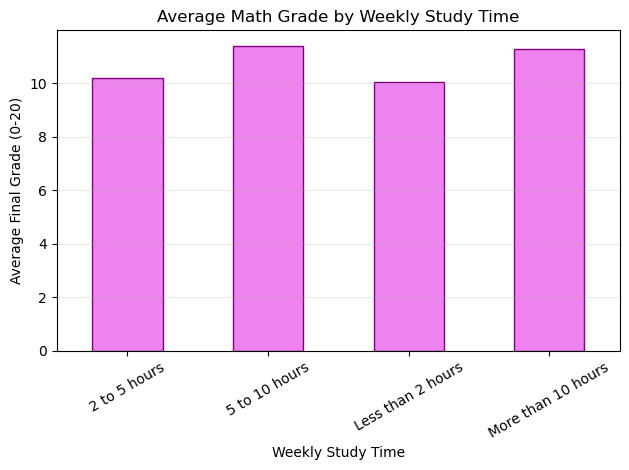

In [22]:
df.groupby("studytime_label")["G3"].mean().plot(kind="bar", color="violet", edgecolor="purple")

plt.title("Average Math Grade by Weekly Study Time")
plt.xlabel("Weekly Study Time")
plt.ylabel("Average Final Grade (0-20)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Grade Distribution and Results

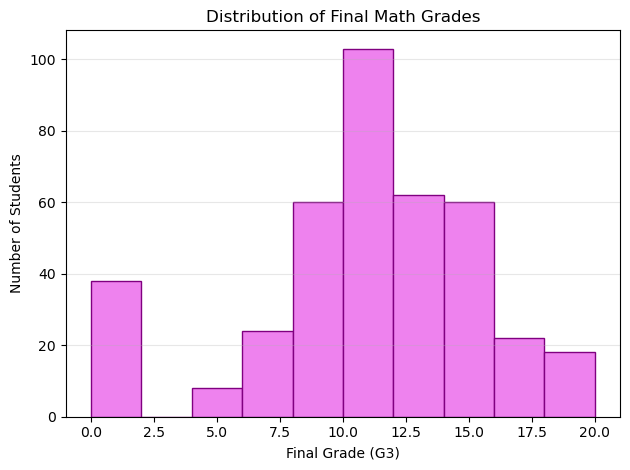

In [23]:
plt.hist(df["G3"], bins=10, color="violet", edgecolor="purple")

plt.title("Distribution of Final Math Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Grouping Students by Final Grade

I used a simple function to group students based on their final grades. In this project, grades of 15 or higher are labeled "Excellent", grades from 10 to below 15 are labeled "Passed", and grades below 10 are labeled "Failed". These are categories I defined for this analysis.

In [24]:
def get_result(grade):
    if grade >= 15:
        return "Excellent"
    elif grade >= 10:
        return "Passed"
    else:
        return "Failed"

In [25]:
df["result"] = df["G3"].apply(get_result)

In [26]:
df[["G3", "result"]].head(10)

,G3,result
0,6,Failed
1,6,Failed
2,10,Passed
3,15,Excellent
4,10,Passed
5,15,Excellent
6,11,Passed
7,6,Failed
8,19,Excellent
9,15,Excellent


In [27]:
df["result"].value_counts()

result
Passed       192
Failed       130
Excellent     73
Name: count, dtype: int64

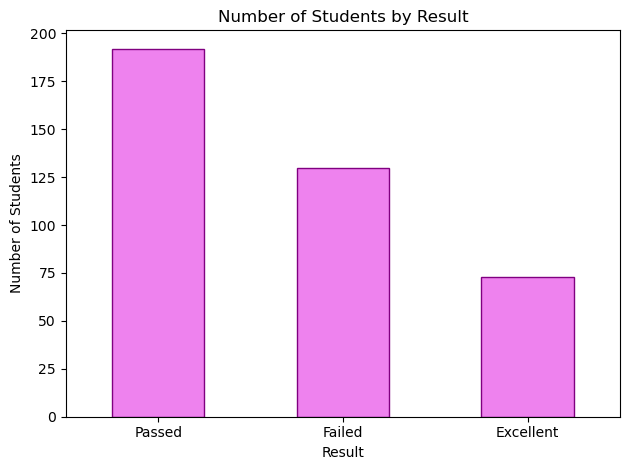

In [28]:
df["result"].value_counts().plot(kind="bar", color="violet", edgecolor="purple")

plt.title("Number of Students by Result")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Practicing Python Loops

In [29]:
for time, label in studytime_labels.items():
    print(time, ":", label)

1 : Less than 2 hours
2 : 2 to 5 hours
3 : 5 to 10 hours
4 : More than 10 hours


In [30]:
for time, label in studytime_labels.items():
    average_grade = df[df["studytime"] == time]["G3"].mean()
    print(label, ":", round(average_grade, 2))

Less than 2 hours : 10.05
2 to 5 hours : 10.17
5 to 10 hours : 11.4
More than 10 hours : 11.26


In [31]:
for index, row in df.head(5).iterrows():
    print(index, row["G3"], row["absences"])

0 6 6
1 6 4
2 10 10
3 15 2
4 10 4


In [32]:
for index, row in df.head(5).iterrows():
    if row["G3"] >= 10:
        print(index, row["G3"], row["absences"])

2 10 10
3 15 2
4 10 4


In [33]:
for index, row in df.head(5).iterrows():
    if row["G3"] >= 10 and row["absences"] > 5:
        print(index, row["G3"], row["absences"])

2 10 10


## Absence Analysis

In [34]:
round(df[df["absences"] > 5]["G3"].mean(), 2)

np.float64(10.84)

In [35]:
round(df[df["absences"] <= 5]["G3"].mean(), 2)

np.float64(10.17)

In [36]:
df[df["absences"] > 5].shape[0]

146

In [37]:
df[df["absences"] <= 5].shape[0]

249

In [38]:
absence_summary = df.groupby(df["absences"] > 5).agg(student_count=("G3", "count"), average_grade=("G3", "mean"))

absence_summary.index = absence_summary.index.map({
    False: "5 or fewer absences",
    True: "More than 5 absences"
})

absence_summary

,student_count,average_grade
absences,,
5 or fewer absences,249,10.168675
More than 5 absences,146,10.835616


In [39]:
absence_summary.sort_values(
    by="average_grade",
    ascending=False
)

,student_count,average_grade
absences,,
More than 5 absences,146,10.835616
5 or fewer absences,249,10.168675


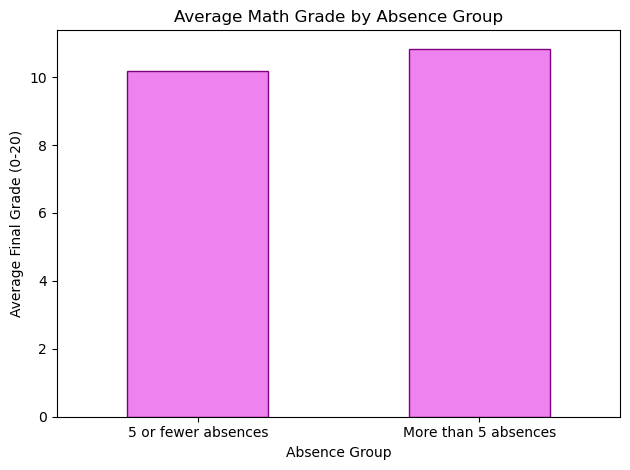

In [40]:
absence_summary["average_grade"].plot(kind="bar", color="violet", edgecolor="purple")

plt.title("Average Math Grade by Absence Group")
plt.xlabel("Absence Group")
plt.ylabel("Average Final Grade (0-20)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
study_summary = df.groupby("studytime_label").agg(student_count=("G3", "count"), average_grade=("G3", "mean"))

study_summary

,student_count,average_grade
studytime_label,,
2 to 5 hours,198,10.171717
5 to 10 hours,65,11.400000
Less than 2 hours,105,10.047619
More than 10 hours,27,11.259259


In [42]:
study_summary.sort_values(by="average_grade", ascending=False)

,student_count,average_grade
studytime_label,,
5 to 10 hours,65,11.400000
More than 10 hours,27,11.259259
2 to 5 hours,198,10.171717
Less than 2 hours,105,10.047619


## What I Found

- The dataset contains 395 students.
- Students who studied 5 to 10 hours per week had the highest average final grade (11.40).
- There were 65 students in this group.
- Students who studied more than 10 hours per week had an average grade of 11.26.
- Students with more than 5 absences had an average grade of 10.84.
- Students with 5 or fewer absences had an average grade of 10.17.

The results show some differences between the groups, but they do not prove that study time or absences directly affect grades. Also, the study-time values represent ranges, not exact hours.